In [1]:
import os
import sys
sys.path.insert(0, "./cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
import glob
import joblib
import umap
from statistics import mean

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/dist_runs/')
#SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [2]:
sys.path.insert(0, "./../../Vector_Similarity/python/TS_SS")
from Vector_Similarity import *

2.23606797749979
0.9999999999999998
0.0004639582566999478


In [3]:
# t = np.linspace(0, 10000, 100001)
t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 0.6

In [4]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'stoch_sim*orig.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
# filenames_sp = [filenames[5], filenames[6], filenames[3], filenames[4], filenames[7], filenames[8], 
#                filenames[0], filenames[1], filenames[2]]
filenames_sp = [filenames[12], filenames[0], filenames[3], filenames[8],
                filenames[12], filenames[12], filenames[17], filenames[23]]
# filenames_sp = [filenames[3], filenames[0], filenames[1], filenames[2],
#                 filenames[4], filenames[5], filenames[6], filenames[7]]
# filenames_sp=filenames
filenames_sp

['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff030_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff099_orig.csv']

In [5]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'ODE_sim*orig.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_sp_ode = [filenames_ode[12], filenames_ode[0], filenames_ode[3], filenames_ode[8],
                    filenames_ode[12], filenames_ode[12], filenames_ode[17], filenames_ode[23]]
# filenames_sp_ode = [filenames_ode[3], filenames_ode[0], filenames_ode[1], filenames_ode[2],
#                     filenames_ode[4], filenames_ode[5], filenames_ode[6], filenames_ode[7]]
#filenames_sp_ode = filenames_ode
filenames_sp_ode


['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff030_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff099_orig.csv']

In [6]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.02
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.05

#reducer save name
r_name = f'reducer_01_04_{init_dt}_{dt}_{window}_{time_step}.sav'

In [7]:
def calc_minmax(filenames, filenames_ode):
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [8]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [9]:
max_prots, min_prots = calc_minmax(filenames, filenames_ode)

In [10]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [11]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [15]:
all_prot_tmp.shape

(319944, 720)

In [13]:
reducer = joblib.load('C:\\Users\\olesk\\data\\reducer_07_25_0.1_0.1_4_0.5.sav')

win_len = int(window/dt)

In [14]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [16]:
vec1=all_prot_tmp[1,:] - all_prot_tmp[0,:]
vec2=all_prot_tmp[10,:] - all_prot_tmp[9,:]

In [25]:
print(Euclidean(vec1,vec2))
print(Cosine(vec1,vec2))
print(TS_SS(vec1,vec2))

1.5160637214736712
0.0707371918856639
0.0010238291808716867


In [17]:
w_len = int(len(all_prot_tmp_ode)/len(filenames_sp))


In [26]:
prot_vec=all_prot_tmp[:w_len,:]
offset=2
v_len=2

In [27]:
prot_inds = np.arange(0,len(prot_vec),offset)

In [28]:
prot_inds

array([    0,     2,     4, ..., 39988, 39990, 39992])

In [34]:
def calc_sim(prot_vec, offset, v_len):
    prot_inds = np.arange(0,len(prot_vec),offset)
    euc_vals = []
    cos_vals = []
    TS_SS_vals = []
    
    for val in range(len(prot_inds)-1):
        vec1=all_prot_tmp[prot_inds[val]+v_len,:] - all_prot_tmp[prot_inds[val],:]
        vec2=all_prot_tmp[prot_inds[val+1]+v_len,:] - all_prot_tmp[prot_inds[val+1],:]
        euc_vals.append(Euclidean(vec1,vec2))
        cos_vals.append(Cosine(vec1,vec2))
        TS_SS_vals.append(TS_SS(vec1,vec2))
        
    return euc_vals, cos_vals, TS_SS_vals

In [35]:
euc_vals, cos_vals, TS_SS_vals = calc_sim(prot_vec, offset, v_len)

In [36]:
log_euc_vals=[math.log(val) for val in euc_vals]
log_TS_SS_vals=[math.log(val) for val in TS_SS_vals]

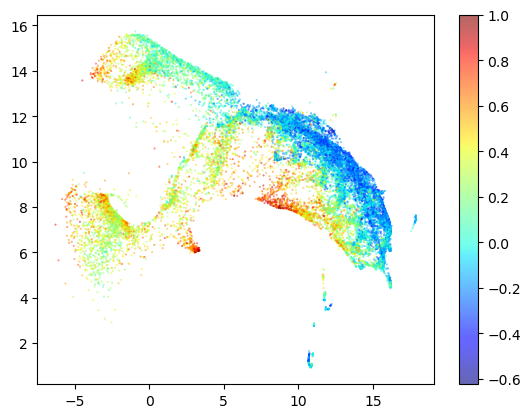

In [37]:
fig1 = plt.figure()

plt.scatter(embedding_all_prot[prot_inds[:-1],0], embedding_all_prot[prot_inds[:-1],1],
           s=0.2, alpha=0.6, c=log_euc_vals, vmax=1, cmap='jet')

plt.colorbar()

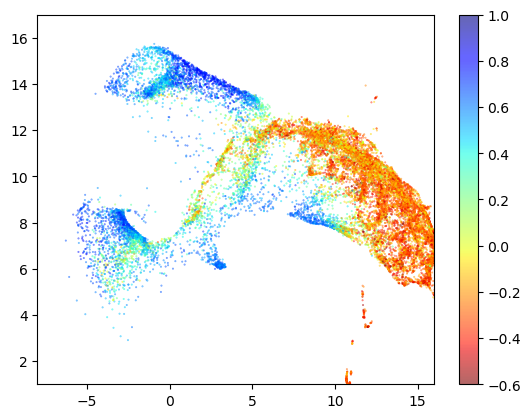

In [38]:
fig1 = plt.figure()

plt.scatter(embedding_all_prot[prot_inds[:-1],0], embedding_all_prot[prot_inds[:-1],1],
           s=0.2, alpha=0.6, vmin=-0.6, vmax=1, c=cos_vals, cmap='jet_r')
plt.ylim(1,17)
plt.xlim(-8,16)
plt.colorbar()

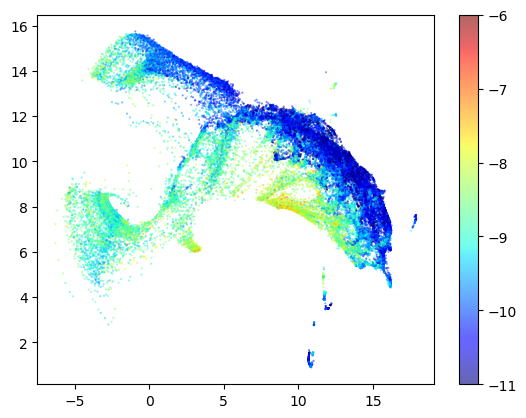

In [339]:
fig1 = plt.figure()

plt.scatter(embedding_all_prot[prot_inds[:-1],0], embedding_all_prot[prot_inds[:-1],1],
           s=0.2, alpha=0.6, c=log_TS_SS_vals, vmin=-11, vmax=-6, cmap='jet')

plt.colorbar()